In [1]:
# --- Imports ---
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models
from sqlalchemy import create_engine, text
from sklearn.model_selection import train_test_split
import numpy as np
import os
import io

from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

In [2]:
# --- ResNet50 Model Setup (Corrected) ---
def create_resnet50_for_9_channels_bigearthnet_hf(num_classes=5):
    """
    Loads ResNet-50 pre-trained on BigEarthNet v2.0 (all Sentinel bands),
    and adapts it for 9-channel input and the specified number of classes.
    """
    # 1. Instantiate a standard ResNet-50 model
    model = models.resnet50(weights=None)

    # 2. IMPORTANT: Modify the first layer to accept 12 channels BEFORE loading weights.
    # The pre-trained model was trained on all 12 Sentinel-2 bands.
    # We must match this architecture to load the weights correctly.
    original_conv1 = model.conv1
    model.conv1 = nn.Conv2d(
        in_channels=12, 
        out_channels=original_conv1.out_channels,
        kernel_size=original_conv1.kernel_size,
        stride=original_conv1.stride,
        padding=original_conv1.padding,
        bias=(original_conv1.bias is not None)
    )

    # 3. Download and load the BigEarthNet v2.0 "all bands" weights
    repo_id = "BIFOLD-BigEarthNetv2-0/resnet50-all-v0.2.0"
    safetensors_path = hf_hub_download(repo_id=repo_id, filename="model.safetensors")
    state_dict = load_file(safetensors_path)
    
    # Now, loading the state dict will work for conv1 as the channels match (12)
    model.load_state_dict(state_dict, strict=False)
    print(f"Loaded pre-trained weights from Hugging Face repo: {repo_id}")

    # 4. Now, adapt the 12-channel layer down to 9 channels for your data
    # We take the pre-trained 12-channel weights and use only the first 9.
    loaded_conv1 = model.conv1
    new_conv1 = nn.Conv2d(
        in_channels=9,
        out_channels=loaded_conv1.out_channels,
        kernel_size=loaded_conv1.kernel_size,
        stride=loaded_conv1.stride,
        padding=loaded_conv1.padding,
        bias=(loaded_conv1.bias is not None)
    )

    with torch.no_grad():
        # Copy the first 9 channels of weights from the loaded 12-channel layer
        new_conv1.weight.data = loaded_conv1.weight.data[:, :9, :, :]
        if loaded_conv1.bias is not None:
            new_conv1.bias.data = loaded_conv1.bias.data

    # Replace the 12-channel layer with our new 9-channel layer
    model.conv1 = new_conv1
    print("Adapted first convolutional layer from 12 down to 9-channel input.")

    # 5. Adapt the final fully connected layer for our number of classes
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)
    
    print(f"ResNet50 model ready. Final layer adapted for {num_classes} classes.")
    return model

In [3]:
# --- Helper function and Dataset Class (re-used from previous script) ---
def get_initial_records_and_map(db_url_str):
    engine = create_engine(db_url_str)
    all_records_from_db, label_map, train_records_list, val_records_list = [], {}, [], []
    try:
        with engine.connect() as conn:
            result = conn.execute(text("""
                SELECT id, surface_group FROM final_balanced_trail_segments
                WHERE image_data IS NOT NULL AND surface_group IS NOT NULL
            """))
            all_records_from_db = result.fetchall()
        if not all_records_from_db: return [], [], {}
        unique_labels = sorted(list(set(r[1] for r in all_records_from_db)))
        label_map = {label: idx for idx, label in enumerate(unique_labels)}
        all_records_with_labels = [(r[0], label_map[r[1]]) for r in all_records_from_db]
        train_records_list, val_records_list = train_test_split(
            all_records_with_labels, test_size=0.2, random_state=42,
            stratify=[r[1] for r in all_records_with_labels] if len(all_records_with_labels) > 1 else None
        )
        print(f"Pre-fetched data: {len(train_records_list)} train, {len(val_records_list)} val records. Label map size: {len(label_map)}")
    except Exception as e: print(f"Error during initial data fetch: {e}")
    finally:
        if engine: engine.dispose()
    return train_records_list, val_records_list, label_map

class TrailSegmentDataset(Dataset):
    def __init__(self, db_url, records_list, label_map, transform=None, for_stats_calc=False):
        self.db_url, self.engine, self.records, self.label_map, self.transform, self.for_stats_calc = \
            db_url, None, records_list, label_map, transform, for_stats_calc
    def _get_engine(self):
        if self.engine is None: self.engine = create_engine(self.db_url)
        return self.engine
    def __len__(self): return len(self.records)
    def __getitem__(self, idx):
        seg_id, label = self.records[idx]
        try:
            with self._get_engine().connect() as conn:
                res = conn.execute(text("SELECT image_data FROM final_balanced_trail_segments WHERE id = :id"), {"id": seg_id})
                image_bytes = res.scalar()
            if image_bytes is None: return (None, label) if self.for_stats_calc else (_ for _ in ()).throw(ValueError(f"Img None for id {seg_id}"))
            image_array = np.load(io.BytesIO(image_bytes)).astype(np.float32)
            return (self.transform(image_array) if self.transform else image_array), label
        except Exception as e:
            print(f"Error in __getitem__ for seg_id {seg_id}: {e}")
            return (None, label) if self.for_stats_calc else (_ for _ in ()).throw(e)


In [4]:
# --- Main Data Preparation ---
db_url = os.getenv('DATABASE_URL', "postgresql://markfinlay:@localhost:5432/osm")
if "localhost" in db_url and os.getenv('DATABASE_URL') is None:
    print("Warning: Using default fallback DATABASE_URL pointing to localhost.")

train_img_records, val_img_records, global_label_map = get_initial_records_and_map(db_url)

# --- Normalization Calculation ---
print("Calculating mean and std for normalization...")
temp_train_dataset = TrailSegmentDataset(db_url, train_img_records, global_label_map, for_stats_calc=True)
all_imgs = [img for img, _ in temp_train_dataset if img is not None]
all_imgs_np = np.stack(all_imgs, axis=0)
channel_means = np.mean(all_imgs_np, axis=(0, 1, 2))
channel_stds = np.std(all_imgs_np, axis=(0, 1, 2))
channel_stds = np.maximum(channel_stds, 1e-6)
print(f"Means: {channel_means.tolist()}\nStds: {channel_stds.tolist()}")

# --- Transforms and DataLoaders ---
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=channel_means.tolist(), std=channel_stds.tolist()),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
])
val_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=channel_means.tolist(), std=channel_stds.tolist()),
])

train_dataset = TrailSegmentDataset(db_url, train_img_records, global_label_map, transform=train_transform)
val_dataset = TrailSegmentDataset(db_url, val_img_records, global_label_map, transform=val_transform)

num_workers = 0
pin_memory = False
if torch.cuda.is_available(): pin_memory = True

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=num_workers, pin_memory=pin_memory)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=num_workers, pin_memory=pin_memory) if val_dataset else None


Pre-fetched data: 98096 train, 24524 val records. Label map size: 5
Calculating mean and std for normalization...
Means: [0.2704830765724182, 0.2651905417442322, 0.24170875549316406, 0.04852844402194023, 0.08895786851644516, 0.10506097972393036, 0.0670185536146164, 0.043866924941539764, 0.1670200675725937]
Stds: [0.657516598701477, 0.6269733309745789, 0.6625603437423706, 0.08884993195533752, 0.1327875852584839, 0.16703945398330688, 0.09218523651361465, 0.061533838510513306, 0.40868088603019714]


In [5]:
# --- Setup for Training ---
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

num_classes = len(global_label_map)
model = create_resnet50_for_9_channels_bigearthnet_hf(num_classes).to(device) # Function name updated
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

# Class weights (code remains the same)
from collections import Counter
train_labels = [label for _, label in train_img_records]
counts = Counter(train_labels)
total = sum(counts.values())
weights = torch.tensor([total / (num_classes * counts.get(i, 1)) for i in range(num_classes)], dtype=torch.float).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)

Using device: mps
Loaded pre-trained weights from Hugging Face repo: BIFOLD-BigEarthNetv2-0/resnet50-all-v0.2.0
Adapted first convolutional layer from 12 down to 9-channel input.
ResNet50 model ready. Final layer adapted for 5 classes.


In [6]:
# Learning Rate Scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=5)

# --- Training Loop ---
epoch_count = 50
best_val_accuracy = 0.0
patience_early_stop = 10
patience_counter = 0
model_save_path = "best_resnet50_BigEarthNET_model.pth"

# NEW: Dictionary to store training history
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': []
}

print("--- Starting ResNet50 Training ---")
for epoch in range(epoch_count):
    model.train()
    running_loss, train_correct, train_total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(dim=1) == labels).sum().item()
        train_total += labels.size(0)

    # Calculate training metrics
    epoch_loss = running_loss / train_total
    epoch_train_accuracy = 100 * train_correct / train_total
    print(f"Epoch [{epoch+1}/{epoch_count}] - Train Loss: {epoch_loss:.4f}, Train Acc: {epoch_train_accuracy:.2f}%")

    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            val_loss += criterion(outputs, labels).item() * images.size(0)
            val_correct += (outputs.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    # Calculate validation metrics
    epoch_val_loss = val_loss / val_total
    epoch_val_accuracy = 100 * val_correct / val_total
    print(f"→ Validation Loss: {epoch_val_loss:.4f}, Validation Acc: {epoch_val_accuracy:.2f}%")

    # Append metrics to history
    history['train_loss'].append(epoch_loss)
    history['train_acc'].append(epoch_train_accuracy)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_accuracy)

    scheduler.step(epoch_val_loss)

    if epoch_val_accuracy > best_val_accuracy:
        best_val_accuracy = epoch_val_accuracy
        patience_counter = 0
        torch.save(model.state_dict(), model_save_path)
        print(f"✓ Saved new best model to {model_save_path} with accuracy: {best_val_accuracy:.2f}%")
    else:
        patience_counter += 1

    if patience_counter >= patience_early_stop:
        print(f"Early stopping triggered after {patience_early_stop} epochs of no improvement.")
        break

print("--- Training complete ---")

--- Starting ResNet50 Training ---
Epoch [1/50] - Train Loss: 1.6358, Train Acc: 31.42%
→ Validation Loss: 1.7556, Validation Acc: 34.68%
✓ Saved new best model to best_resnet50_BigEarthNET_model.pth with accuracy: 34.68%
Epoch [2/50] - Train Loss: 1.4684, Train Acc: 34.92%
→ Validation Loss: 1.5241, Validation Acc: 35.13%
✓ Saved new best model to best_resnet50_BigEarthNET_model.pth with accuracy: 35.13%
Epoch [3/50] - Train Loss: 1.3859, Train Acc: 37.62%
→ Validation Loss: 1.3456, Validation Acc: 39.40%
✓ Saved new best model to best_resnet50_BigEarthNET_model.pth with accuracy: 39.40%
Epoch [4/50] - Train Loss: 1.3525, Train Acc: 39.12%
→ Validation Loss: 1.3521, Validation Acc: 39.88%
✓ Saved new best model to best_resnet50_BigEarthNET_model.pth with accuracy: 39.88%
Epoch [5/50] - Train Loss: 1.3313, Train Acc: 40.95%
→ Validation Loss: 1.3600, Validation Acc: 39.32%
Epoch [6/50] - Train Loss: 1.3147, Train Acc: 42.15%
→ Validation Loss: 1.3145, Validation Acc: 41.57%
✓ Saved new

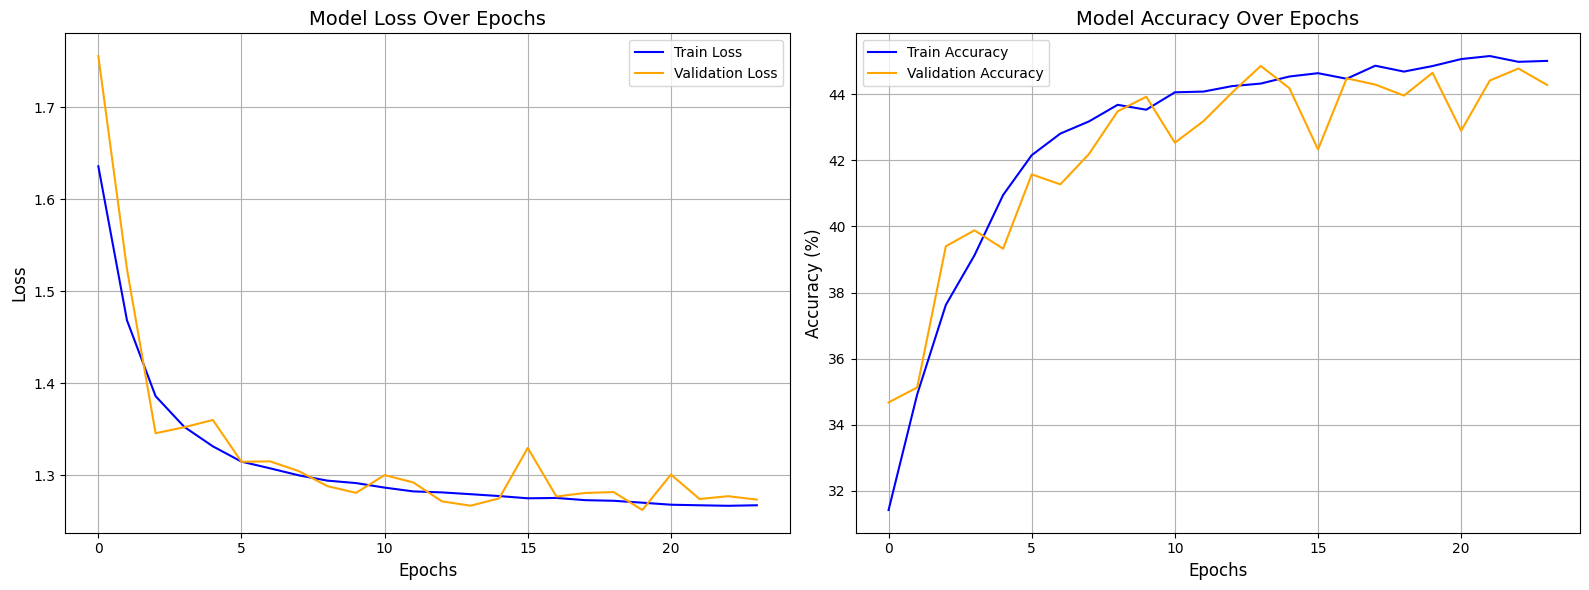

In [7]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot Loss ---
ax1.plot(history['train_loss'], label='Train Loss', color='blue')
ax1.plot(history['val_loss'], label='Validation Loss', color='orange')
ax1.set_title('Model Loss Over Epochs', fontsize=14)
ax1.set_xlabel('Epochs', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.legend()
ax1.grid(True)

# --- Plot Accuracy ---
ax2.plot(history['train_acc'], label='Train Accuracy', color='blue')
ax2.plot(history['val_acc'], label='Validation Accuracy', color='orange')
ax2.set_title('Model Accuracy Over Epochs', fontsize=14)
ax2.set_xlabel('Epochs', fontsize=12)
ax2.set_ylabel('Accuracy (%)', fontsize=12)
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

Loaded pre-trained weights from Hugging Face repo: BIFOLD-BigEarthNetv2-0/resnet50-all-v0.2.0
Adapted first convolutional layer from 12 down to 9-channel input.
ResNet50 model ready. Final layer adapted for 5 classes.


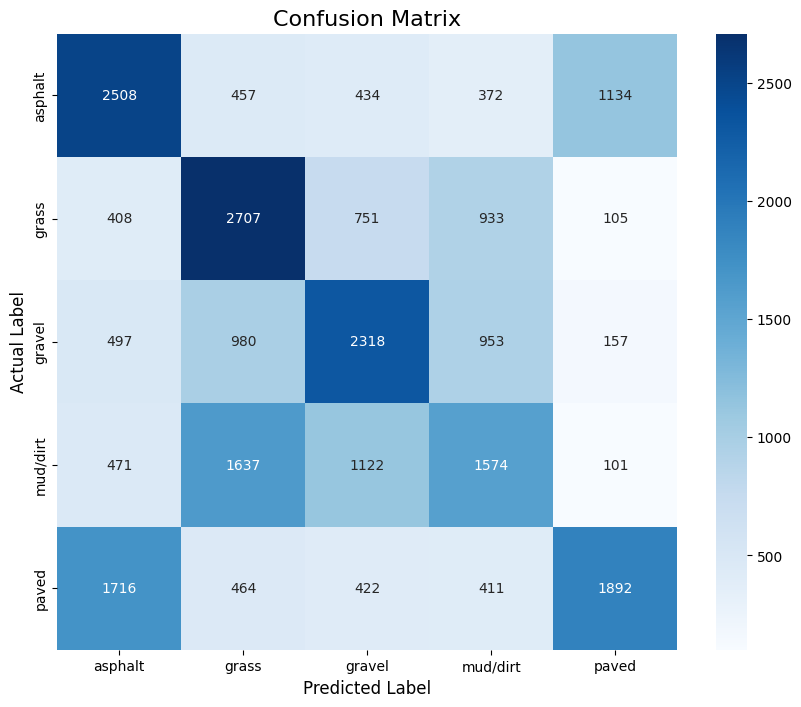

In [8]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import torch

# 1. Initialize and load the best model
# Ensure the model architecture is defined and pass the number of classes
model = create_resnet50_for_9_channels_bigearthnet_hf(num_classes=len(global_label_map))
# Load the state dictionary from your saved model file
model.load_state_dict(torch.load(model_save_path, map_location=device))
# Move the model to the appropriate device (GPU/CPU)
model.to(device)
# Set the model to evaluation mode
model.eval()

# 2. Get predictions on the validation set
all_labels = []
all_preds = []

with torch.no_grad(): # Disable gradient calculation for inference
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = model(images)
        # Get the predicted class index with the highest score
        preds = torch.argmax(outputs, dim=1)
        
        # Move predictions and labels to CPU and store them
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 3. Compute and plot the confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Get class names from the global label map, ensuring they are in the correct order
class_names = [item[0] for item in sorted(global_label_map.items(), key=lambda item: item[1])]

# Plotting the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)

plt.title('Confusion Matrix', fontsize=16)
plt.ylabel('Actual Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.show()

In [9]:
from sklearn.metrics import classification_report

# Ensure 'all_labels', 'all_preds', and 'global_label_map' exist from the
# previous cell where the confusion matrix was calculated.

# Get class names in the correct order for the report
class_names = [item[0] for item in sorted(global_label_map.items(), key=lambda item: item[1])]

# Generate and print the classification report
report = classification_report(all_labels, all_preds, target_names=class_names)

print("--- Classification Report ---")
print(report)

--- Classification Report ---
              precision    recall  f1-score   support

     asphalt       0.45      0.51      0.48      4905
       grass       0.43      0.55      0.49      4904
      gravel       0.46      0.47      0.47      4905
    mud/dirt       0.37      0.32      0.34      4905
       paved       0.56      0.39      0.46      4905

    accuracy                           0.45     24524
   macro avg       0.45      0.45      0.45     24524
weighted avg       0.45      0.45      0.45     24524

